# Interactive Diffusion Demo with Gradio

Build an interactive image-generation demo using a pretrained diffusion model from Hugging Face and a Gradio interface.


In [1]:
import gradio as gr
import torch
from diffusers import DiffusionPipeline
from PIL import Image


In [2]:
pipe = DiffusionPipeline.from_pretrained("stable-diffusion-v1-5/stable-diffusion-v1-5", dtype=torch.bfloat16, device_map="cuda")

prompt = "Astronaut in a jungle, cold color palette, muted colors, detailed, 8k"
image = pipe(prompt).images[0]

Keyword arguments {'dtype': torch.bfloat16} are not expected by StableDiffusionPipeline and will be ignored.


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

RuntimeError: CUDA error: CUDA-capable device(s) is/are busy or unavailable
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


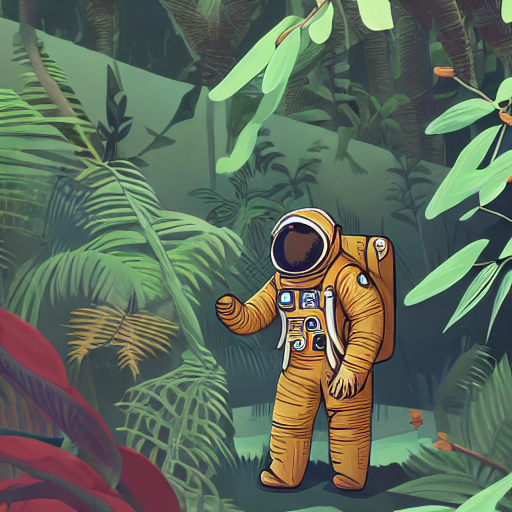

In [ ]:
image

In [ ]:
RNG = torch.Generator()
RNG.manual_seed(42)

def create_image(prompt, negative_prompt, num_inference_steps, guidance_scale,generator = RNG):
    return pipe(
        prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=int(num_inference_steps),
        guidance_scale=float(guidance_scale),
    ).images[0]


In [ ]:
demo = gr.Interface(
    fn=create_image,
    inputs=[
        gr.Textbox(label="Prompt", placeholder="Describe the image you want to generate"),
        gr.Textbox(label="Negative prompt", placeholder="Describe what to avoid"),
        gr.Slider(
            minimum=1,
            maximum=100,
            value=50,
            step=1,
            label="Inference steps",
            info="More steps take longer and may improve image quality.",
        ),
        gr.Slider(
            minimum=0,
            maximum=20,
            value=7.5,
            step=0.1,
            label="Guidance scale",
            info="Higher values encourage closer adherence to the prompt.",
        ),
    ],
    outputs=gr.Image(label="Generated image"),
    title="Diffusion Image Generator",
)

demo.launch()


* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


/run/media/myskiharka/New Volume/HandsonGenAi/.venv/lib/python3.10/site-packages/gradio/routes.py:1368: StarletteDeprecationWarning: 'HTTP_422_UNPROCESSABLE_ENTITY' is deprecated. Use 'HTTP_422_UNPROCESSABLE_CONTENT' instead.
  return await queue_join_helper(body, request, username)


  0%|          | 0/100 [00:00<?, ?it/s]

/run/media/myskiharka/New Volume/HandsonGenAi/.venv/lib/python3.10/site-packages/gradio/routes.py:1368: StarletteDeprecationWarning: 'HTTP_422_UNPROCESSABLE_ENTITY' is deprecated. Use 'HTTP_422_UNPROCESSABLE_CONTENT' instead.
  return await queue_join_helper(body, request, username)


  0%|          | 0/100 [00:00<?, ?it/s]

/run/media/myskiharka/New Volume/HandsonGenAi/.venv/lib/python3.10/site-packages/gradio/routes.py:1368: StarletteDeprecationWarning: 'HTTP_422_UNPROCESSABLE_ENTITY' is deprecated. Use 'HTTP_422_UNPROCESSABLE_CONTENT' instead.
  return await queue_join_helper(body, request, username)


  0%|          | 0/100 [00:00<?, ?it/s]